In [1]:
import pandas as pd
from pathlib import Path

In [2]:
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
def contains_all_tags(tags_str, image_tags):
    return tags_str.apply(lambda s: all(t in [x.strip() for x in s.split('|')] for t in image_tags))

In [4]:
def get_unmatched_images(model, checkpoint, filter_tags, k_value):
    data_dir = Path("data/files")
    tag = f"{model}-{checkpoint}"

    bench = pd.read_csv(data_dir / f"benchmarks_{tag}.csv")
    bench['mod'] = bench['mod'].fillna('')
    images = pd.read_csv(data_dir / f"image_records.csv")
    images['modification'] = images['modification'].fillna('')
    df = pd.merge(images,bench, 
                        left_on=['folder_path','image_name','modification'], 
                        right_on=['folder','image','mod'],
                        how='right')
    df = df.loc[df['metric'] == 'cosine'].copy()
    df = df.loc[contains_all_tags(df['tags'].fillna(''), filter_tags)]

            

    # keep only images whose top_k score is not 1.0
    failed = df[(df["benchmark_metric"] == f"top_{k_value}") & (df["unit_score"] != 1.0)]

    sims = pd.read_csv(data_dir / f"similarities_{tag}.csv")
    sims = sims.loc[sims['metric'] == 'cosine'].copy()
    sims['query_mod'] = sims['query_mod'].fillna('')
    sims['instr_mod'] = sims['instr_mod'].fillna('')

    keys = ["query_folder", "query_image", "query_mod"]
    sims_idx = sims.set_index(keys).sort_index()
    out_cols = ["instr_folder", "instr_image", "instr_mod", "score"]

    results = {}
    for row in failed.itertuples(index=False):
        key = (row.folder, row.image, row.mod)
        try:
            topk = sims_idx.loc[[key]]
        except KeyError:
            continue
        results[key] = topk.sort_values("score", ascending=False).head(k_value)[out_cols].reset_index(drop=True)
    return results


In [5]:
def display_unmatched_images(model, checkpoint, tags, k_value:int):
    data_dir = Path("data/files")
    res = get_unmatched_images(model, checkpoint, tags, k_value=k_value)
    images = pd.read_csv(data_dir / f"image_records.csv")
    images['modification'] = images['modification'].fillna('')
    image_key = ["folder_path","image_name","modification"]
    images = images.set_index(image_key).sort_index()
    for key, df in res.items():
        try:
            query_record = images.loc[key]
        except KeyError:
            continue
        fig, axes = plt.subplots(1, len(df) + 1, figsize=(4 * (len(df) + 1), 4))
        query_path = Path(key[0]) / key[1]
        axes[0].imshow(Image.open(query_path))
        axes[0].set_title(f"Query: {key[1]}, step:{query_record.step_number}", fontsize=8)
        for ax, row in zip(axes[1:], df.itertuples(index=False)):
            ax.imshow(Image.open(Path(row.instr_folder) / row.instr_image))
            try:
                instr_record = images.loc[(row.instr_folder,row.instr_image,row.instr_mod)]
            except KeyError:
                continue
            ax.set_title(f"{instr_record.step_number}\nscore: {row.score:.4f}", fontsize=8)
        for ax in axes:
            ax.axis("off")
        plt.show()
        plt.close(fig)

/tmp/ipykernel_93204/4165640900.py:6: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  bench['mod'] = bench['mod'].fillna('')
/tmp/ipykernel_93204/4165640900.py:8: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  images['modification'] = images['modification'].fillna('')
/tmp/ipykernel_93204/4165640900.py:23: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  sims['query_mod'] = sims['query_mod'].fillna('')
/tmp/ipykernel_93204/4165640900.py:24: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, c

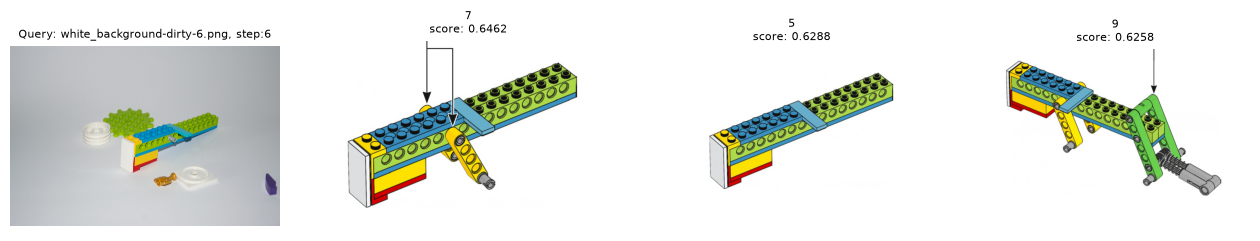

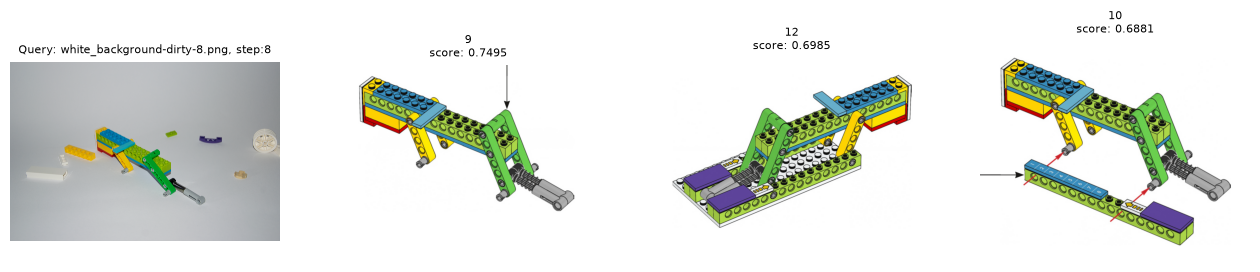

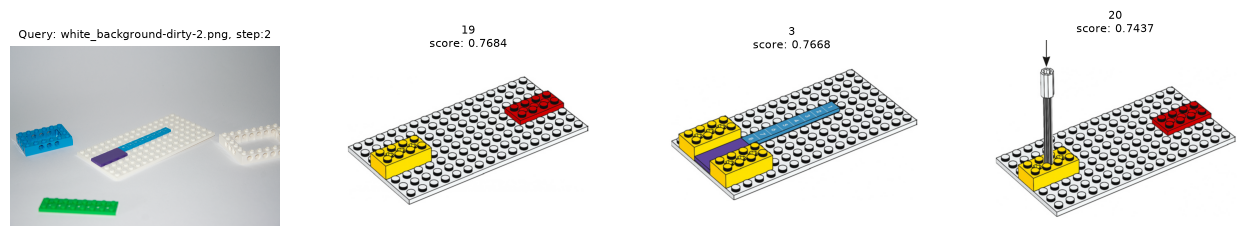

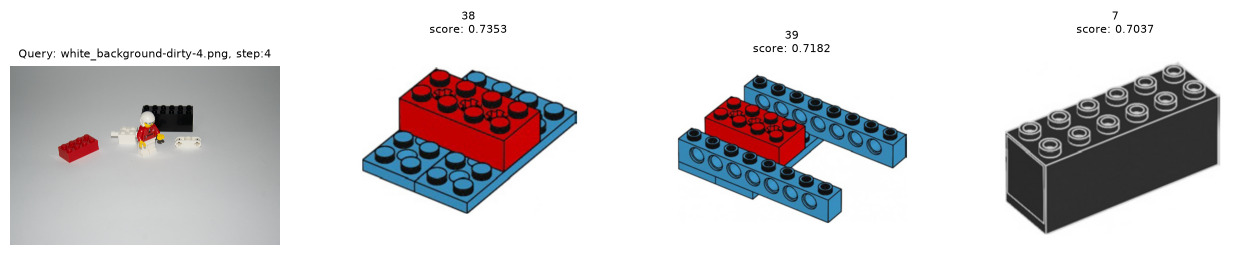

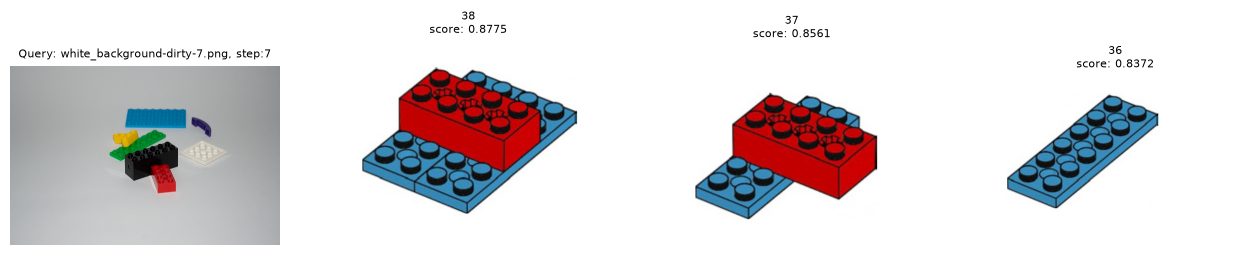

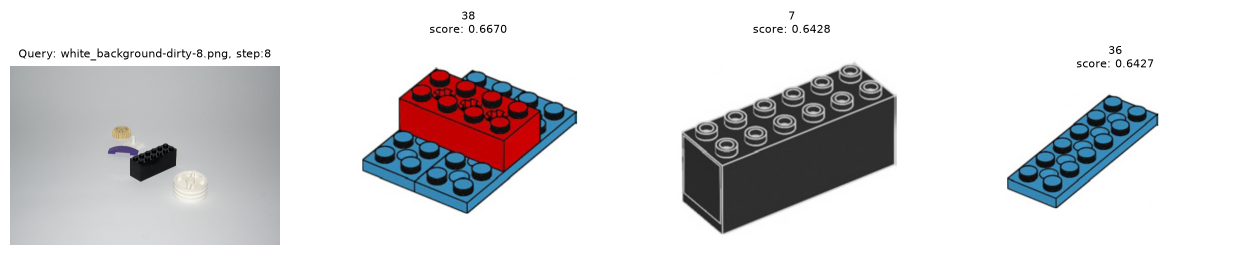

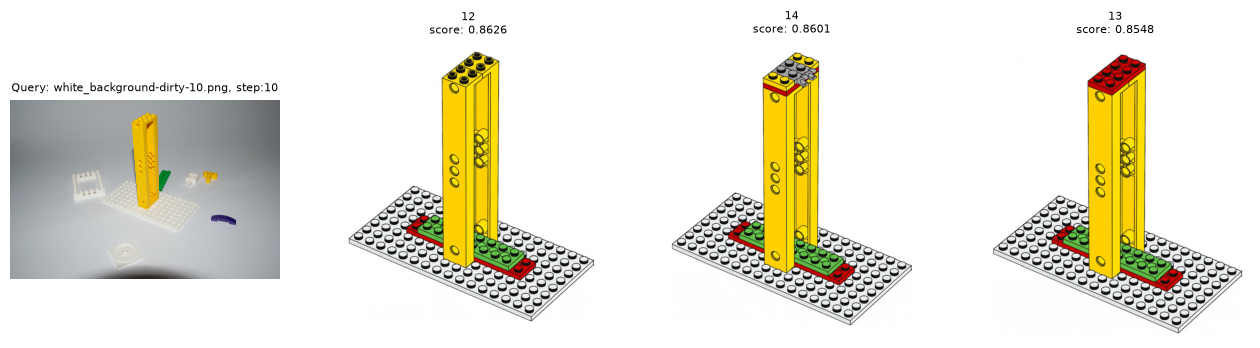

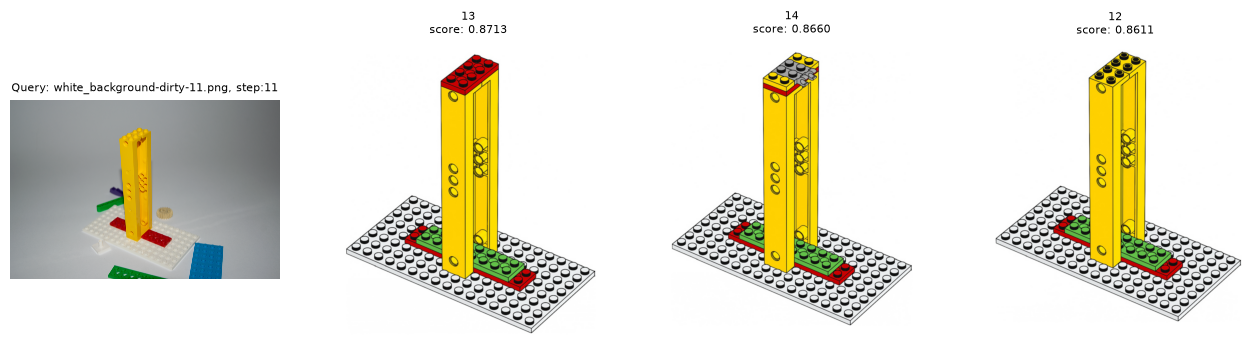

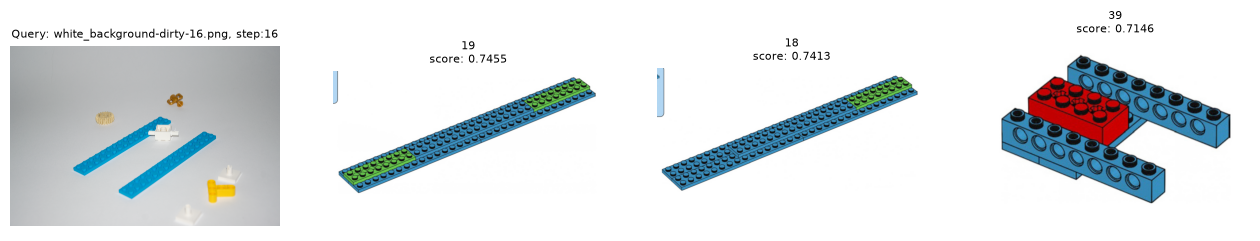

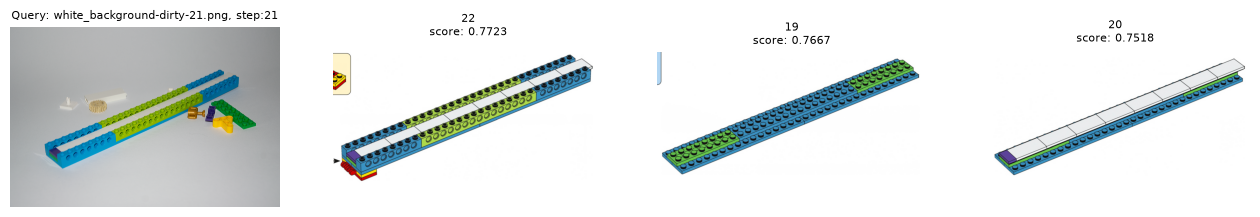

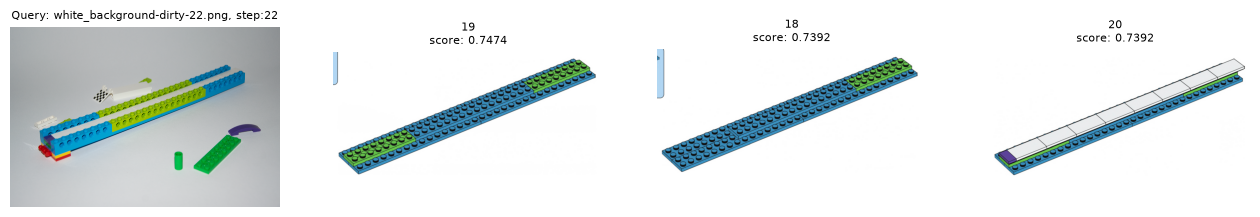

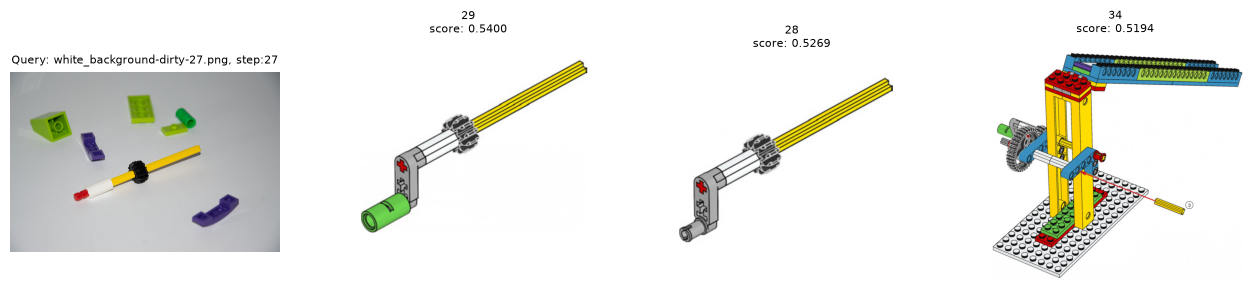

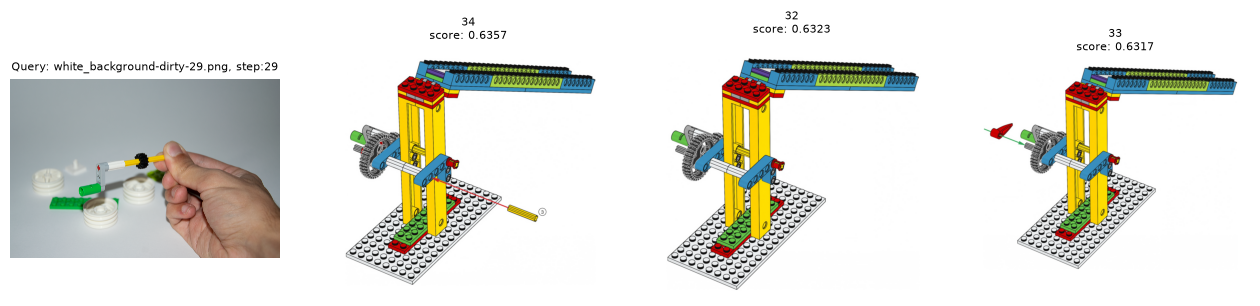

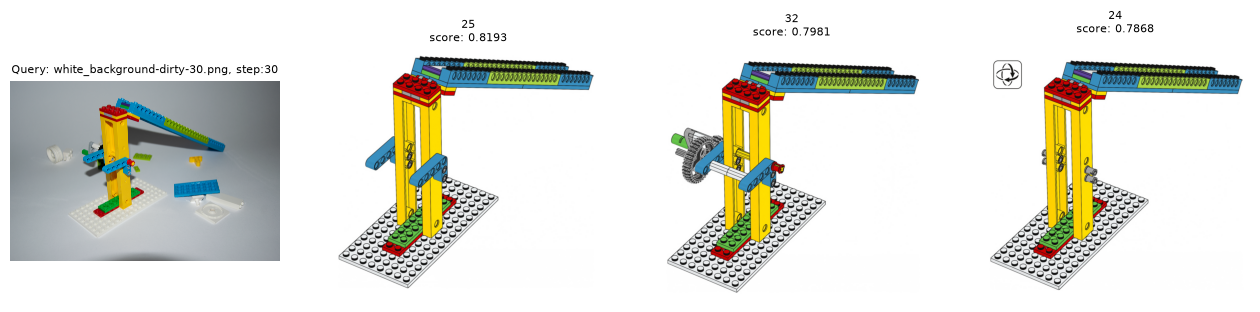

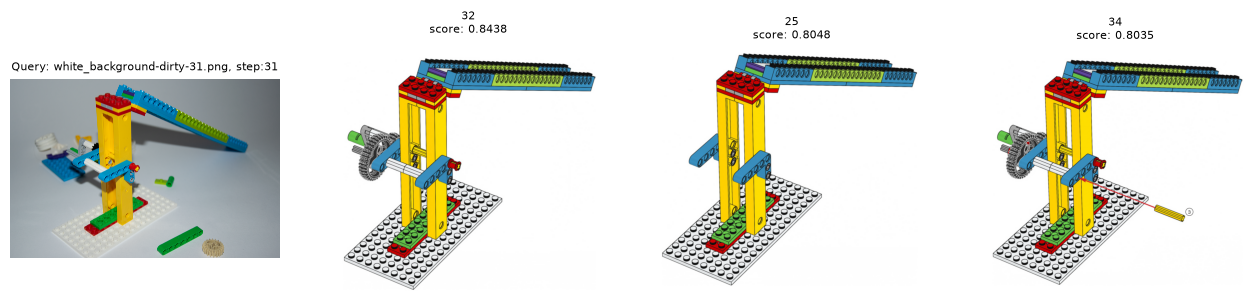

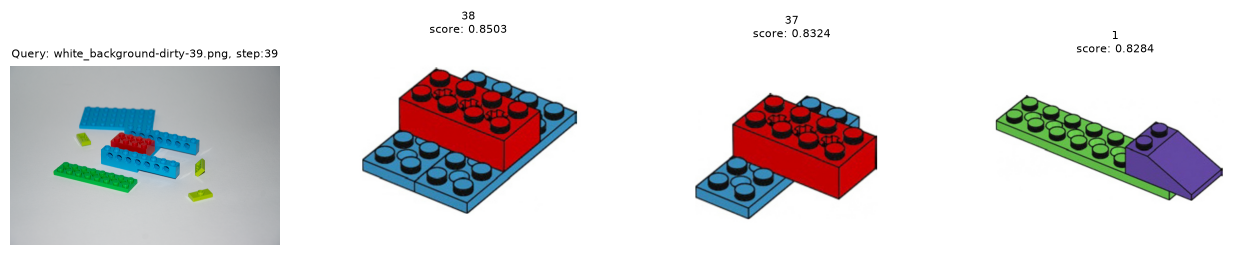

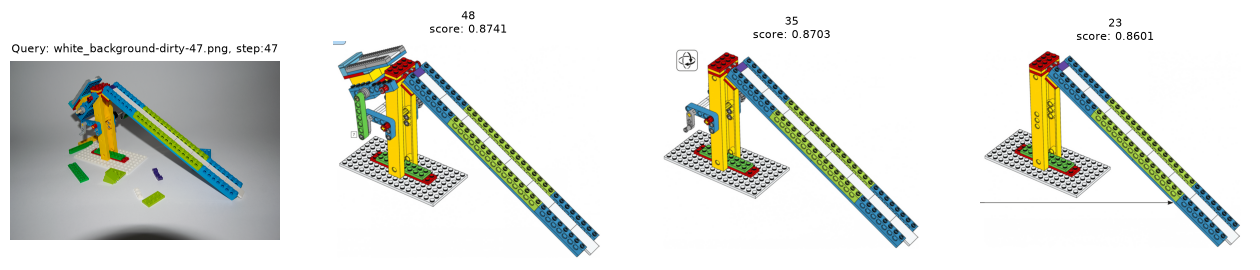

In [8]:
display_unmatched_images("dinov3_only_CLS","facebook_dinov3-vith16plus-pretrain-lvd1689m", ['white_background','dirty'],3)